# Analiza rynku mieszkaniowego w Warszawie (2023–2026)
**Źródło danych:** Rejestr Cen Nieruchomości (RCN) m.st. Warszawy (`warszawa_mieszkania_full.csv`) wzbogacony o zmienne przestrzenne (dzielnica, odległość od centrum i stacji metra, liczba sklepów, parków, szkół i przystanków).

### Zakres analizy:
1. **Etap 2. Audyt i czyszczenie danych:**
   - Weryfikacja braków danych oraz kolumn pustych i stałych.
   - Kontrola rodzaju transakcji (wolny rynek vs przetargi, egzekucje, bonifikaty) oraz rodzaju rynku (pierwotny vs wtórny).
   - Identyfikacja sprzedaży udziałów ułamkowych (`NIER_UDZIAL != '1/1'`).
   - Rozwiązanie problemu transakcji wielolokalowych (wybór `LOK_CENA_BRUTTO` zamiast łącznej `TRAN_CENA_BRUTTO`, wykluczenie niejednoznacznych pakietów i duplikatów).
   - Filtrowanie wartości odstających (ceny zerowe/nierealne, powierzchnie użytkowe, ceny za $m^2$).
   - Eksport oczyszczonego zbioru `warszawa_mieszkania_clean.csv`.
2. **Etap 3. Eksploracyjna Analiza Danych (EDA):**
   - Rozkład cen za $m^2$ i wolumen transakcji według 18 dzielnic Warszawy.
   - Trendy cenowe i wolumenowe w latach 2023–2026 (ujęcie roczne i kwartalne).
   - Porównanie rynku pierwotnego i wtórnego (rozkłady gęstości, kategorie metrażu, premia cenowa w dzielnicach).
   - Zależność cen za $m^2$ od odległości od metra (`distance_metro_m`), dostępu do parków (`parks_1000m`) i sklepów (`shops_500m`), wraz z macierzą korelacji i mapą przestrzenną.

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
plt.rcParams['figure.dpi'] = 130
sns.set_theme(style="whitegrid", font_scale=1.05)

df_raw = pd.read_csv('/content/sample_data/warszawa_mieszkania_full.csv', on_bad_lines='warn')
print(f"Wymiary surowego zbioru: {df_raw.shape[0]:,} wierszy x {df_raw.shape[1]} kolumn")
df_raw.head(3)

Wymiary surowego zbioru: 165,119 wierszy x 45 kolumn


,gid,SERWIS_RCN,TERYT,TRAN_PRZESTRZEN_NAZW,TRAN_LOKALNY_ID_IIP,TRAN_WERSJA_ID,TRAN_OZNACZENIE_TRANS,TRAN_RODZAJ_TRANS,TRAN_RODZAJ_RYNKU,TRAN_SPRZEDAJACY,TRAN_KUPUJACY,TRAN_CENA_BRUTTO,TRAN_VAT,DOK_OZNACZENIE,DOK_DATA,DOK_TWORCA,NIER_RODZAJ,NIER_PRAWO,NIER_UDZIAL,NIER_POW_GRUNTU,NIER_OPIS,NIER_CENA_BRUTTO,NIER_VAT,LOK_ID_LOKALU,LOK_FUNKCJA,LOK_LICZBA_IZB,LOK_NR_KOND,LOK_POW_UZYT,LOK_POW_PRZYN,LOK_CENA_BRUTTO,LOK_VAT,LOK_INFO,LOK_ADRES,northing_2180,easting_2180,latitude,longitude,warsaw_location_ok,distance_center_km,district,shops_500m,parks_1000m,schools_1000m,bus_stops_500m,distance_metro_m
0,"23,325,006.00",NaN,1465,PL.PZGiK.5346.RCN,17d4f86c-da86-406c-a0fe-b8d497f2bdf7,2023-07-28T14:18:02Z,492063,wolnyRynek,rynekPierwotny,osobaPrawna,osobaFizyczna,"558,089.00",NaN,264/2023,2023-01-10,ILONA SĄDEL-BENDKOWSKA,nieruchomoscLokalowa,wlasnoscLokaluWrazZPrawemZwiazanym,1/1,NaN,NaN,"558,089.00",NaN,146513_8.0814.1/6.4_BUD.99_LOK,mieszkalna,2.00,7.00,39.33,NaN,558089.0,NaN,NaN,MSC:Warszawa;UL:ulica Bokserska;NR_PORZ:73,"480,194.06","636,007.78",52.17,20.99,True,6.86,Ursynów,11.00,1.00,2.00,3.00,"2,526.45"
1,"23,325,070.00",NaN,1465,PL.PZGiK.5346.RCN,e1f9e3c6-d7c0-481f-bb74-29d631920d37,2023-08-17T14:07:19Z,493422,wolnyRynek,rynekWtorny,osobaFizyczna,osobaFizyczna,"1,351,000.00",100074.07,227/2023,2023-01-12,PIOTR PRZYBYSZ,nieruchomoscLokalowa,wlasnoscLokaluWrazZPrawemZwiazanym,1/1,NaN,NaN,"1,351,000.00",100074.07,146511_8.0821.95/10.1_BUD.4_LOK,mieszkalna,4.00,1.00,122.48,NaN,1351000.0,"100,074.07",NaN,MSC:Warszawa;UL:ulica Budowlana;NR_PORZ:5,"492,464.80","638,049.01",52.28,21.02,True,5.58,Targówek,14.00,0.00,4.00,5.00,"1,453.44"
2,"23,325,073.00",NaN,1465,PL.PZGiK.5346.RCN,a5d3008e-9f85-49f1-ad4d-462240957eeb,2026-02-06T15:57:35Z,493523,wolnyRynek,rynekWtorny,osobaFizyczna,osobaFizyczna,"225,310.00",NaN,981/2023,2023-01-13,MAREK HRYMAK,nieruchomoscLokalowa,wlasnoscLokaluWrazZPrawemZwiazanym,1/1,NaN,NaN,"225,310.00",NaN,146512_8.1107.28.1_BUD.1_LOK,mieszkalna,2.00,1.00,23.82,NaN,225310.0,NaN,NaN,MSC:Warszawa;UL:ulica Franciszka Adolfa Achera...,"482,918.01","629,137.68",52.20,20.89,True,8.83,Ursus,119.00,13.00,11.00,16.00,"4,986.04"


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [7]:
# with open('/content/sample_data/warszawa_mieszkania_full.csv', encoding='utf-8') as f:
#     for i, line in enumerate(f, 1):
#         if i in (1, 2042):
#             print(f"Linia {i}: {line[:250]}")

Linia 1: ﻿gid,SERWIS_RCN,TERYT,TRAN_PRZESTRZEN_NAZW,TRAN_LOKALNY_ID_IIP,TRAN_WERSJA_ID,TRAN_OZNACZENIE_TRANS,TRAN_RODZAJ_TRANS,TRAN_RODZAJ_RYNKU,TRAN_SPRZEDAJACY,TRAN_KUPUJACY,TRAN_CENA_BRUTTO,TRAN_VAT,DOK_OZNACZENIE,DOK_DATA,DOK_TWORCA,NIER_RODZAJ,NIER_PRAWO
Linia 2042: 23327829,,1465,PL.PZGiK.5346.RCN,f2d1ae6e-deac-4220-bde6-e11b60f7fe86,2024-10-14T16:47:41Z,548708,wolnyRynek,rynekPierwotny,osobaFizyczna,osobaFizyczna,477736.0,,4859/2024,20244-a9b2-c84407be0288,2026-02-10T13:59:37Z,598966,wolnyRynek,rynekPierwotny,


## Etap 2. Audyt i czyszczenie danych

### 2.1. Audyt braków danych oraz kolumn pustych i stałych

In [9]:
missing = df_raw.isnull().sum()
missing_pct = (missing / len(df_raw) * 100).round(2)
missing_report = pd.DataFrame({
    'Liczba_brakow': missing,
    'Procent_brakow_%': missing_pct,
    'Unikalne_wartosci': df_raw.nunique(dropna=True),
    'Typ_danych': df_raw.dtypes
}).sort_values('Liczba_brakow', ascending=False)

print("Kolumny zawierające braki danych:")
print(missing_report[missing_report['Liczba_brakow'] > 0])

cols_empty = missing_report[missing_report['Procent_brakow_%'] > 99].index.tolist()
cols_const = missing_report[missing_report['Unikalne_wartosci'] <= 1].index.tolist()
print(f"\nKolumny puste (>99% NaN): {cols_empty}")
print(f"Kolumny stałe (<=1 unikalna wartość): {cols_const}")

Kolumny zawierające braki danych:
                       Liczba_brakow  Procent_brakow_%  Unikalne_wartosci  \
SERWIS_RCN                    165118            100.00                  1   
LOK_INFO                      165101             99.99                 16   
NIER_OPIS                     165101             99.99                 17   
NIER_POW_GRUNTU               165100             99.99                 18   
TRAN_VAT                      150831             91.35               8267   
LOK_VAT                       146980             89.01              11839   
NIER_VAT                      146954             89.00              11721   
LOK_POW_PRZYN                 128371             77.74               3285   
LOK_NR_KOND                     1104              0.67                 99   
NIER_CENA_BRUTTO                 943              0.57              52208   
LOK_CENA_BRUTTO                  934              0.57              51945   
distance_metro_m                  32      

### 2.2. Audyt merytoryczny: tryb transakcji, udziały w nieruchomości, transakcje wielolokalowe i wartości odstające

Kluczowe aspekty weryfikowane w danych RCN:
1. **Tryb transakcji (`TRAN_RODZAJ_TRANS`)**: wykluczenie sprzedaży przetargowych, egzekucyjnych i z bonifikatą (np. wykup komunalny za 70 PLN).
2. **Udziały w nieruchomości (`NIER_UDZIAL`)**: przy sprzedaży ułamkowej (np. `1/2`, `1/4`) kolumna `LOK_POW_UZYT` podaje powierzchnię całego lokalu, co sztucznie zaniża cenę za $m^2$.
3. **Transakcje wielolokalowe i cena lokalu vs cena całego aktu**:
   - `TRAN_CENA_BRUTTO` obejmuje cały akt notarialny (często mieszkanie + garaż + komórka lokatorska albo pakiet lokali).
   - `LOK_CENA_BRUTTO` określa cenę samego lokalu mieszkalnego i stanowi właściwą podstawę do wyznaczenia ceny za $m^2$.
   - Akty wielolokalowe (`DOK_OZNACZENIE` + `DOK_DATA` + `DOK_TWORCA` z liczbą wierszy > 1), w których brakuje `LOK_CENA_BRUTTO` lub powielono w niej `TRAN_CENA_BRUTTO`, są usuwane jako niejednoznaczne.

In [11]:
import numpy as np

df = df_raw.copy()
df['DOK_DATA'] = pd.to_datetime(df['DOK_DATA'], errors='coerce')

# Konwersja kolumn cenowych i powierzchni na typ numeryczny (float)
num_cols = ['LOK_CENA_BRUTTO', 'NIER_CENA_BRUTTO', 'TRAN_CENA_BRUTTO', 'LOK_POW_UZYT']
for col in num_cols:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace(',', '.', regex=False).str.replace(' ', '', regex=False),
        errors='coerce'
    )

# Klucz pojedynczego aktu notarialnego
df['akt_id'] = (
    df['DOK_OZNACZENIE'].astype(str) + "_" +
    df['DOK_DATA'].dt.strftime('%Y-%m-%d') + "_" +
    df['DOK_TWORCA'].astype(str)
)
df['lokali_w_akcie'] = df.groupby('akt_id')['gid'].transform('count')

# Cena samego lokalu: preferujemy LOK_CENA_BRUTTO; dla pojedynczych lokali dopuszczamy uzupełnienie z NIER/TRAN
df['cena_lokalu'] = df['LOK_CENA_BRUTTO']
mask_single_fill = df['cena_lokalu'].isna() & (df['lokali_w_akcie'] == 1)
df.loc[mask_single_fill, 'cena_lokalu'] = (
    df.loc[mask_single_fill, 'NIER_CENA_BRUTTO']
    .fillna(df.loc[mask_single_fill, 'TRAN_CENA_BRUTTO'])
)

# Obliczenie ceny za m² z zabezpieczeniem przed dzieleniem przez 0
df['cena_m2'] = df['cena_lokalu'] / df['LOK_POW_UZYT'].replace(0, np.nan)

anomalie = {
    '1. Tryb inny niż wolnyRynek': int((df['TRAN_RODZAJ_TRANS'] != 'wolnyRynek').sum()),
    '2. Brak określenia rodzaju rynku (pierwotny/wtórny)': int(df['TRAN_RODZAJ_RYNKU'].isna().sum()),
    '3. Prawo inne niż własność lokalu': int((df['NIER_PRAWO'] != 'wlasnoscLokaluWrazZPrawemZwiazanym').sum()),
    '4. Udział inny niż pełna własność (NIER_UDZIAL != 1/1)': int((df['NIER_UDZIAL'].isna() | (df['NIER_UDZIAL'] != '1/1')).sum()),
    '5. Akt wielolokalowy bez ceny jednostkowej lokalu': int(((df['lokali_w_akcie'] > 1) & df['LOK_CENA_BRUTTO'].isna()).sum()),
    '6. Akt wielolokalowy z powieloną ceną pakietu': int(((df['lokali_w_akcie'] > 1) & (np.abs(df['cena_lokalu'] - df['TRAN_CENA_BRUTTO']) < 1)).sum()),
    '7. Duplikaty (ten sam lokal, data, cena)': int(df.duplicated(subset=['LOK_ID_LOKALU', 'DOK_DATA', 'cena_lokalu']).sum()),
    '8. Cena lokalu <= 0 PLN': int((df['cena_lokalu'] <= 0).sum()),
    '9. Cena lokalu < 80 000 PLN': int((df['cena_lokalu'] < 80_000).sum()),
    '10. Powierzchnia użytkowa < 12 m² lub > 350 m²': int(((df['LOK_POW_UZYT'] < 12) | (df['LOK_POW_UZYT'] > 350)).sum()),
    '11. Podejrzana cena/m² (< 4 000 lub > 45 000 PLN/m²)': int(((df['cena_m2'] < 4_000) | (df['cena_m2'] > 45_000)).sum()),
}

for k, v in anomalie.items():
    print(f"{k:<56}: {v:>6,}")

1. Tryb inny niż wolnyRynek                             :    199
2. Brak określenia rodzaju rynku (pierwotny/wtórny)     :      8
3. Prawo inne niż własność lokalu                       :     54
4. Udział inny niż pełna własność (NIER_UDZIAL != 1/1)  :  3,882
5. Akt wielolokalowy bez ceny jednostkowej lokalu       :    857
6. Akt wielolokalowy z powieloną ceną pakietu           : 117,562
7. Duplikaty (ten sam lokal, data, cena)                : 75,415
8. Cena lokalu <= 0 PLN                                 :      0
9. Cena lokalu < 80 000 PLN                             :    421
10. Powierzchnia użytkowa < 12 m² lub > 350 m²          :     45
11. Podejrzana cena/m² (< 4 000 lub > 45 000 PLN/m²)    :  1,848


### 2.3. Sekwencyjny pipeline czyszczenia danych i zapis zbioru gotowego do analizy

In [12]:
audit_log = []
def log_step(df_curr, step_name):
    audit_log.append({
        'Etap_czyszczenia': step_name,
        'Pozostalo_wierszy': len(df_curr),
        'Usunieto_w_kroku': (audit_log[-1]['Pozostalo_wierszy'] - len(df_curr)) if audit_log else 0,
        'Procent_poczatku_%': round(len(df_curr) / len(df) * 100, 2)
    })

log_step(df, "0. Zbiór surowy")

# Krok 1: Wolny rynek, znany segment rynku i pełna własność lokalu
df_clean = df[
    (df['TRAN_RODZAJ_TRANS'] == 'wolnyRynek') &
    (df['TRAN_RODZAJ_RYNKU'].notna()) &
    (df['NIER_PRAWO'] == 'wlasnoscLokaluWrazZPrawemZwiazanym')
].copy()
log_step(df_clean, "1. Tylko wolny rynek i własność lokalu")

# Krok 2: Wykluczenie sprzedaży udziałów ułamkowych
df_clean = df_clean[df_clean['NIER_UDZIAL'] == '1/1'].copy()
log_step(df_clean, "2. Pełny udział (NIER_UDZIAL == '1/1')")

# Krok 3: Wykluczenie niejednoznacznych transakcji wielolokalowych
cond_bad_bundle = (
    (df_clean['lokali_w_akcie'] > 1) &
    (df_clean['LOK_CENA_BRUTTO'].isna() | (np.abs(df_clean['cena_lokalu'] - df_clean['TRAN_CENA_BRUTTO']) < 1))
)
df_clean = df_clean[~cond_bad_bundle & df_clean['cena_lokalu'].notna()].copy()
log_step(df_clean, "3. Oczyszczenie transakcji wielolokalowych")

# Krok 4: Usunięcie duplikatów tego samego lokalu w tej samej dacie i cenie
df_clean = df_clean.drop_duplicates(subset=['LOK_ID_LOKALU', 'DOK_DATA', 'cena_lokalu']).copy()
log_step(df_clean, "4. Usunięcie duplikatów transakcji")

# Krok 5: Filtr powierzchni (12–350 m²) i ceny lokalu (>= 80 tys. PLN)
df_clean = df_clean[
    (df_clean['LOK_POW_UZYT'] >= 12.0) &
    (df_clean['LOK_POW_UZYT'] <= 350.0) &
    (df_clean['cena_lokalu'] >= 80_000.0)
].copy()
log_step(df_clean, "5. Filtr powierzchni (12–350 m²) i ceny (>= 80k)")

# Krok 6: Filtr ekstremalnych cen/m² (4 000 – 45 000 PLN/m²)
df_clean = df_clean[
    (df_clean['cena_m2'] >= 4_000.0) &
    (df_clean['cena_m2'] <= 45_000.0)
].copy()
log_step(df_clean, "6. Filtr ceny/m² (4 000 – 45 000 PLN/m²)")

# Usunięcie kolumn pustych i technicznych stałych
cols_to_drop = ['SERWIS_RCN', 'NIER_POW_GRUNTU', 'NIER_OPIS', 'LOK_INFO', 'TERYT',
                'TRAN_PRZESTRZEN_NAZW', 'NIER_RODZAJ', 'LOK_FUNKCJA', 'warsaw_location_ok']
df_clean = df_clean.drop(columns=[c for c in cols_to_drop if c in df_clean.columns])

# Zmienne pomocnicze do EDA
df_clean['rok'] = df_clean['DOK_DATA'].dt.year
df_clean['kwartal'] = df_clean['DOK_DATA'].dt.to_period('Q').astype(str)
df_clean['miesiac'] = df_clean['DOK_DATA'].dt.to_period('M').astype(str)
df_clean['rynek'] = df_clean['TRAN_RODZAJ_RYNKU'].map({
    'rynekPierwotny': 'Rynek pierwotny',
    'rynekWtorny': 'Rynek wtórny'
})
df_clean['strefa_metro'] = pd.cut(
    df_clean['distance_metro_m'],
    bins=[0, 500, 1000, 2000, 4000, np.inf],
    labels=['< 500 m', '500–1000 m', '1–2 km', '2–4 km', '> 4 km']
)
df_clean['kategoria_metrazu'] = pd.cut(
    df_clean['LOK_POW_UZYT'],
    bins=[0, 35, 50, 70, 100, np.inf],
    labels=['Kawalerki (<35 m²)', 'Małe (35–50 m²)', 'Średnie (50–70 m²)', 'Duże (70–100 m²)', 'Apartamenty (>100 m²)']
)

audit_summary = pd.DataFrame(audit_log)
print(audit_summary.to_string(index=False))

df_clean.to_csv('warszawa_mieszkania_clean.csv', index=False)
print(f"\nZapisano oczyszczony zbiór: warszawa_mieszkania_clean.csv ({df_clean.shape[0]:,} wierszy, {df_clean.shape[1]} kolumn)")

                                Etap_czyszczenia  Pozostalo_wierszy  Usunieto_w_kroku  Procent_poczatku_%
                                 0. Zbiór surowy             165119                 0              100.00
          1. Tylko wolny rynek i własność lokalu             164877               242               99.85
          2. Pełny udział (NIER_UDZIAL == '1/1')             161051              3826               97.54
      3. Oczyszczenie transakcji wielolokalowych              45824            115227               27.75
              4. Usunięcie duplikatów transakcji              29905             15919               18.11
5. Filtr powierzchni (12–350 m²) i ceny (>= 80k)              29875                30               18.09
        6. Filtr ceny/m² (4 000 – 45 000 PLN/m²)              29792                83               18.04

Zapisano oczyszczony zbiór: warszawa_mieszkania_clean.csv (29,792 wierszy, 46 kolumn)


Statystyki kluczowych zmiennych po czyszczeniu:
                     count       mean        std        min         5%  \
cena_lokalu      29,792.00 920,769.02 578,306.99 115,000.00 408,295.70   
LOK_POW_UZYT     29,792.00      59.32      27.49      12.90      30.21   
cena_m2          29,792.00  15,535.96   4,675.92   4,016.13   9,184.99   
distance_metro_m 29,789.00   2,917.03   2,324.49      28.81     344.40   

                        50%          95%           max  
cena_lokalu      774,609.00 1,900,000.00 10,400,000.00  
LOK_POW_UZYT          53.00       112.87        327.93  
cena_m2           14,973.26    23,765.07     44,844.25  
distance_metro_m   2,295.72     7,446.60     14,630.98  


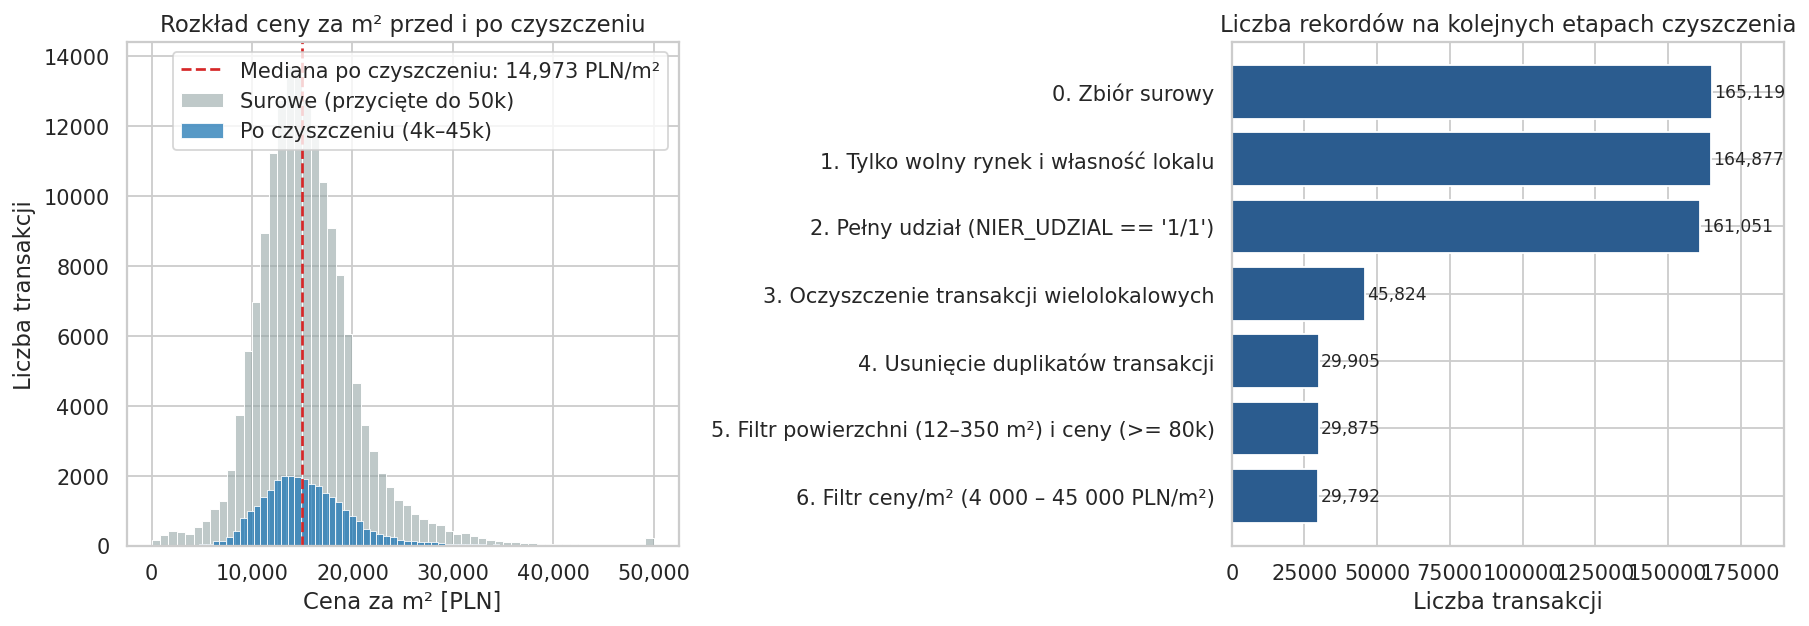

In [13]:
stats_clean = df_clean[['cena_lokalu', 'LOK_POW_UZYT', 'cena_m2', 'distance_center_km', 'distance_metro_m']].describe(
    percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]
).T[['count', 'mean', 'std', 'min', '5%', '50%', '95%', 'max']]
print("Statystyki kluczowych zmiennych po czyszczeniu:")
print(stats_clean)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df['cena_m2'].clip(0, 50000), bins=60, color='#95a5a6', alpha=0.6, label='Surowe (przycięte do 50k)', ax=axes[0])
sns.histplot(df_clean['cena_m2'], bins=60, color='#1f77b4', alpha=0.75, label='Po czyszczeniu (4k–45k)', ax=axes[0])
axes[0].axvline(df_clean['cena_m2'].median(), color='#d62728', linestyle='--', linewidth=1.5,
                label=f"Mediana po czyszczeniu: {df_clean['cena_m2'].median():,.0f} PLN/m²")
axes[0].set_title('Rozkład ceny za m² przed i po czyszczeniu')
axes[0].set_xlabel('Cena za m² [PLN]')
axes[0].set_ylabel('Liczba transakcji')
axes[0].xaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
axes[0].legend()

bars = axes[1].barh(audit_summary['Etap_czyszczenia'][::-1], audit_summary['Pozostalo_wierszy'][::-1], color='#2b5c8f')
axes[1].set_title('Liczba rekordów na kolejnych etapach czyszczenia')
axes[1].set_xlabel('Liczba transakcji')
axes[1].set_xlim(0, len(df) * 1.15)
for bar in bars:
    w = bar.get_width()
    axes[1].text(w + 800, bar.get_y() + bar.get_height()/2, f"{int(w):,}", va='center', fontsize=9.5)

plt.tight_layout()
plt.show()

## Etap 3. Eksploracyjna Analiza Danych (EDA)

### 3.1. Ceny mieszkań i wolumen transakcji według dzielnic Warszawy

Ranking dzielnic Warszawy według mediany ceny za m² (2023–2026):
                Liczba_transakcji  Mediana_cena_m2  Srednia_cena_m2  \
district                                                              
Żoliborz                      543        21,823.30        21,322.63   
Śródmieście                   961        21,641.42        23,122.27   
4                               1        21,108.66        21,108.66   
Wola                         2950        18,771.37        19,319.60   
Mokotów                      3277        17,419.86        17,860.23   
Wilanów                      1782        17,111.54        17,190.02   
Ochota                        701        16,635.61        16,883.58   
Ursynów                      1591        16,435.64        16,175.99   
Bielany                      1219        15,884.48        15,868.52   
Bemowo                       1820        15,254.79        15,202.12   
Praga Południe               2535        15,252.88        15,381.16   
Praga Północ

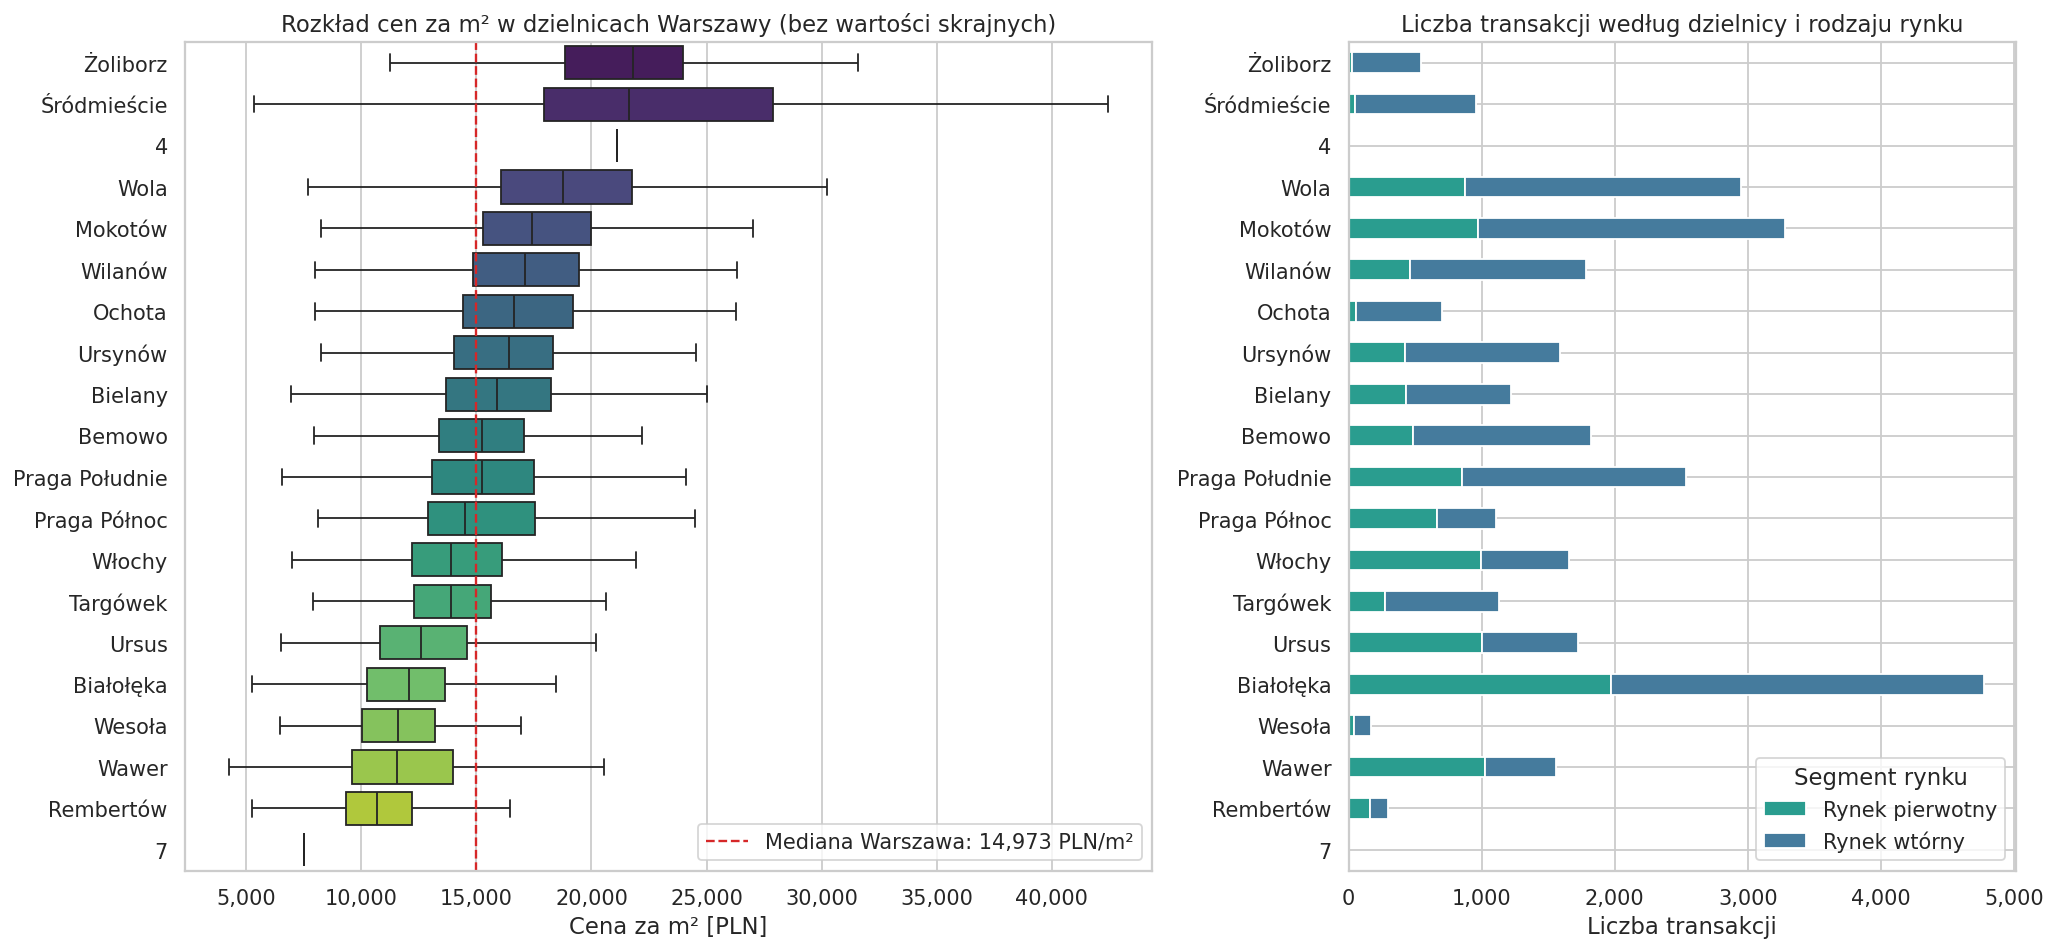

In [14]:
district_stats = df_clean.groupby('district').agg(
    Liczba_transakcji=('gid', 'count'),
    Mediana_cena_m2=('cena_m2', 'median'),
    Srednia_cena_m2=('cena_m2', 'mean'),
    Q25_cena_m2=('cena_m2', lambda x: x.quantile(0.25)),
    Q75_cena_m2=('cena_m2', lambda x: x.quantile(0.75)),
    Mediana_cena_calk=('cena_lokalu', 'median'),
    Mediana_metraz=('LOK_POW_UZYT', 'median'),
    Udzial_pierwotny_pct=('rynek', lambda x: (x == 'Rynek pierwotny').mean() * 100)
).sort_values('Mediana_cena_m2', ascending=False)

print("Ranking dzielnic Warszawy według mediany ceny za m² (2023–2026):")
print(district_stats)

order_dist = district_stats.index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(16, 7.5), gridspec_kw={'width_ratios': [1.45, 1]})

sns.boxplot(
    data=df_clean, y='district', x='cena_m2', order=order_dist,
    palette='viridis', showfliers=False, ax=axes[0]
)
axes[0].axvline(df_clean['cena_m2'].median(), color='#d62728', linestyle='--', linewidth=1.3,
                label=f"Mediana Warszawa: {df_clean['cena_m2'].median():,.0f} PLN/m²")
axes[0].set_title('Rozkład cen za m² w dzielnicach Warszawy (bez wartości skrajnych)')
axes[0].set_xlabel('Cena za m² [PLN]')
axes[0].set_ylabel('')
axes[0].xaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
axes[0].legend(loc='lower right')

dist_market = df_clean.groupby(['district', 'rynek']).size().unstack(fill_value=0).loc[order_dist]
dist_market[['Rynek pierwotny', 'Rynek wtórny']].plot(
    kind='barh', stacked=True, color=['#2a9d8f', '#457b9d'], ax=axes[1]
)
axes[1].invert_yaxis()
axes[1].set_title('Liczba transakcji według dzielnicy i rodzaju rynku')
axes[1].set_xlabel('Liczba transakcji')
axes[1].set_ylabel('')
axes[1].xaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
axes[1].legend(title='Segment rynku', loc='lower right')

plt.tight_layout()
plt.show()

### 3.2. Trendy cenowe i wolumen transakcji w latach 2023–2026

Podsumowanie roczne (2023–2026):
      Transakcje  Mediana_cena_m2  Srednia_cena_m2  Mediana_cena_lokalu  \
rok                                                                       
2023        8275        13,191.15        13,624.96           680,000.00   
2024        9269        15,455.95        15,901.21           800,000.00   
2025       10323        15,645.74        16,367.72           800,000.00   
2026        1925        16,803.95        17,531.65           900,000.00   

      Mediana_metraz  Zmiana_r_r_%  
rok                                 
2023           53.35           NaN  
2024           53.36         17.17  
2025           51.79          1.23  
2026           55.00          7.40  


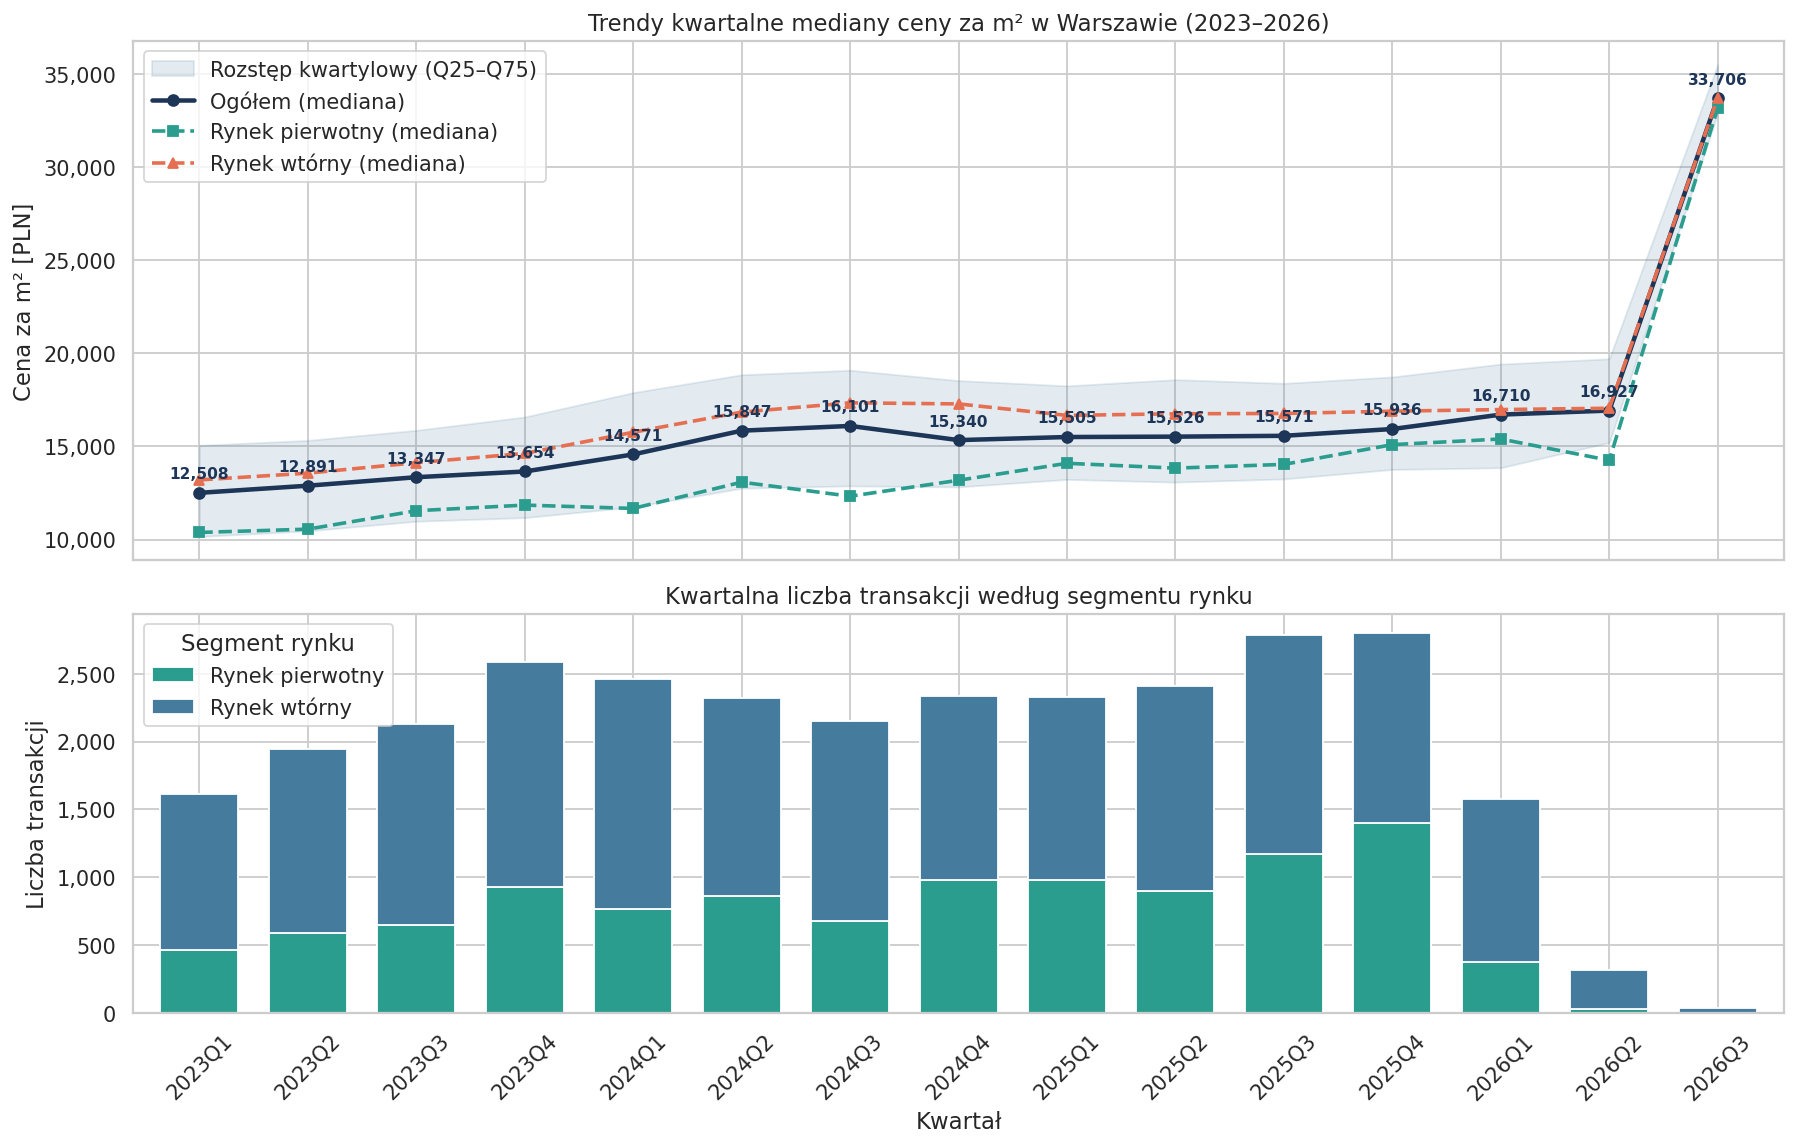

In [15]:
yearly_stats = df_clean.groupby('rok').agg(
    Transakcje=('gid', 'count'),
    Mediana_cena_m2=('cena_m2', 'median'),
    Srednia_cena_m2=('cena_m2', 'mean'),
    Mediana_cena_lokalu=('cena_lokalu', 'median'),
    Mediana_metraz=('LOK_POW_UZYT', 'median')
)
yearly_stats['Zmiana_r_r_%'] = yearly_stats['Mediana_cena_m2'].pct_change() * 100
print("Podsumowanie roczne (2023–2026):")
print(yearly_stats)

q_stats = df_clean.groupby('kwartal').agg(
    Transakcje=('gid', 'count'),
    Mediana_cena_m2=('cena_m2', 'median'),
    Q25=('cena_m2', lambda x: x.quantile(0.25)),
    Q75=('cena_m2', lambda x: x.quantile(0.75))
).reset_index()
q_market = df_clean.groupby(['kwartal', 'rynek'])['cena_m2'].median().unstack().reset_index()

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True, gridspec_kw={'height_ratios': [1.3, 1]})

axes[0].fill_between(q_stats['kwartal'], q_stats['Q25'], q_stats['Q75'], color='#457b9d', alpha=0.15, label='Rozstęp kwartylowy (Q25–Q75)')
axes[0].plot(q_stats['kwartal'], q_stats['Mediana_cena_m2'], marker='o', linewidth=2.5, color='#1d3557', label='Ogółem (mediana)')
axes[0].plot(q_market['kwartal'], q_market['Rynek pierwotny'], marker='s', linestyle='--', linewidth=2, color='#2a9d8f', label='Rynek pierwotny (mediana)')
axes[0].plot(q_market['kwartal'], q_market['Rynek wtórny'], marker='^', linestyle='--', linewidth=2, color='#e76f51', label='Rynek wtórny (mediana)')
axes[0].set_title('Trendy kwartalne mediany ceny za m² w Warszawie (2023–2026)')
axes[0].set_ylabel('Cena za m² [PLN]')
axes[0].yaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
axes[0].legend(loc='upper left')

for _, row in q_stats.iterrows():
    axes[0].annotate(f"{row['Mediana_cena_m2']:,.0f}", (row['kwartal'], row['Mediana_cena_m2']),
                     textcoords="offset points", xytext=(0, 8), ha='center', fontsize=8.5, fontweight='bold', color='#1d3557')

q_vol = df_clean.groupby(['kwartal', 'rynek']).size().unstack(fill_value=0)
q_vol[['Rynek pierwotny', 'Rynek wtórny']].plot(kind='bar', stacked=True, color=['#2a9d8f', '#457b9d'], ax=axes[1], width=0.72)
axes[1].set_title('Kwartalna liczba transakcji według segmentu rynku')
axes[1].set_xlabel('Kwartał')
axes[1].set_ylabel('Liczba transakcji')
axes[1].yaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(title='Segment rynku', loc='upper left')

plt.tight_layout()
plt.show()

### 3.3. Porównanie rynku pierwotnego i wtórnego

Porównanie rynku pierwotnego i wtórnego:
rynek                   Rynek pierwotny  Rynek wtórny
Liczba_transakcji             10,765.00     19,027.00
Udzial_pct                        36.13         63.87
Mediana_cena_m2               13,235.32     15,973.02
Srednia_cena_m2               13,947.62     16,434.60
Q25_cena_m2                   11,015.14     13,379.96
Q75_cena_m2                   15,929.61     18,763.09
Mediana_cena_lokalu          697,582.54    814,000.00
Mediana_powierzchni               53.12         53.00
Srednia_liczba_izb                 2.67          2.88
Mediana_odl_centrum_km             7.76          6.73


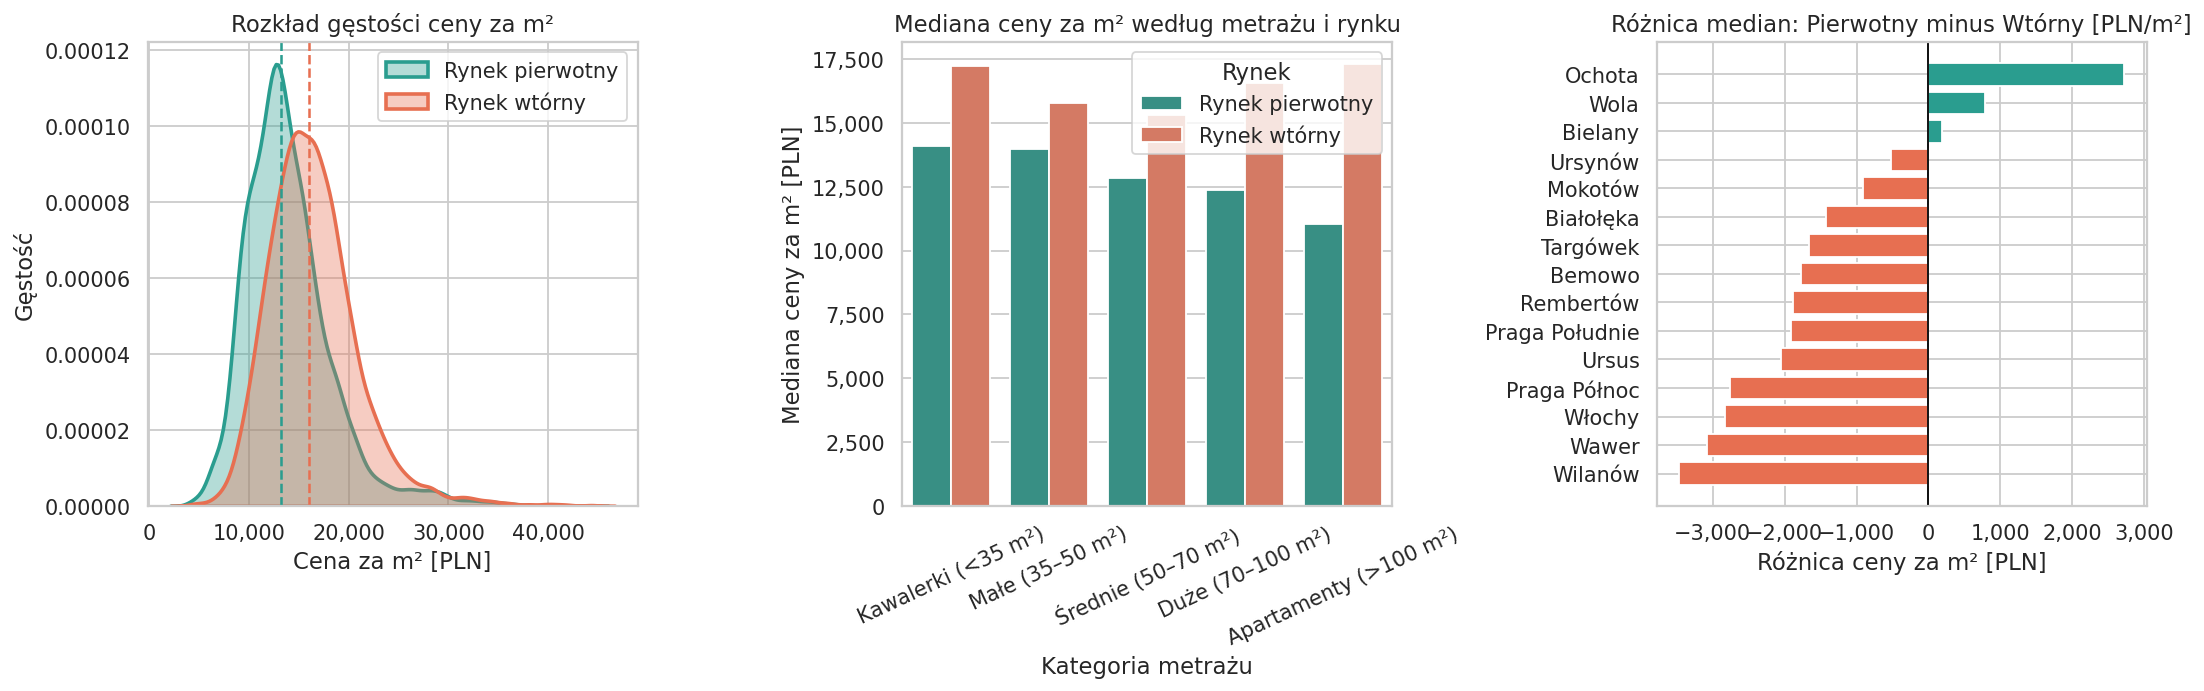

In [17]:
# Konwersja kolumn numerycznych używanych w agregacji (szczególnie LOK_LICZBA_IZB)
cols_to_numeric = ['LOK_LICZBA_IZB', 'cena_m2', 'cena_lokalu', 'LOK_POW_UZYT', 'distance_center_km']
for col in cols_to_numeric:
    if col in df_clean.columns:
        df_clean[col] = pd.to_numeric(
            df_clean[col].astype(str).str.replace(',', '.', regex=False).str.strip(),
            errors='coerce'
        )

market_comp = df_clean.groupby('rynek').agg(
    Liczba_transakcji=('gid', 'count'),
    Udzial_pct=('gid', lambda x: len(x) / len(df_clean) * 100),
    Mediana_cena_m2=('cena_m2', 'median'),
    Srednia_cena_m2=('cena_m2', 'mean'),
    Q25_cena_m2=('cena_m2', lambda x: x.quantile(0.25)),
    Q75_cena_m2=('cena_m2', lambda x: x.quantile(0.75)),
    Mediana_cena_lokalu=('cena_lokalu', 'median'),
    Mediana_powierzchni=('LOK_POW_UZYT', 'median'),
    Srednia_liczba_izb=('LOK_LICZBA_IZB', 'mean'),
    Mediana_odl_centrum_km=('distance_center_km', 'median')
)
print("Porównanie rynku pierwotnego i wtórnego:")
print(market_comp.T)

fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))

for m_name, color in [('Rynek pierwotny', '#2a9d8f'), ('Rynek wtórny', '#e76f51')]:
    sub = df_clean[df_clean['rynek'] == m_name]
    sns.kdeplot(sub['cena_m2'], fill=True, alpha=0.35, linewidth=2, color=color, label=m_name, ax=axes[0])
    axes[0].axvline(sub['cena_m2'].median(), color=color, linestyle='--', linewidth=1.4)
axes[0].set_title('Rozkład gęstości ceny za m²')
axes[0].set_xlabel('Cena za m² [PLN]')
axes[0].set_ylabel('Gęstość')
axes[0].xaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
axes[0].legend()

sns.barplot(
    data=df_clean, x='kategoria_metrazu', y='cena_m2', hue='rynek',
    estimator=np.median, errorbar=None, palette=['#2a9d8f', '#e76f51'], ax=axes[1]
)
axes[1].set_title('Mediana ceny za m² według metrażu i rynku')
axes[1].set_xlabel('Kategoria metrażu')
axes[1].set_ylabel('Mediana ceny za m² [PLN]')
axes[1].yaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
axes[1].tick_params(axis='x', rotation=25)
axes[1].legend(title='Rynek')

piv = df_clean.pivot_table(index='district', columns='rynek', values='cena_m2', aggfunc='median')
cnt = df_clean.pivot_table(index='district', columns='rynek', values='gid', aggfunc='count')
valid_dist = cnt[(cnt['Rynek pierwotny'] >= 50) & (cnt['Rynek wtórny'] >= 50)].index
piv_valid = piv.loc[valid_dist].copy()
piv_valid['Premia_pierwotny_PLN'] = piv_valid['Rynek pierwotny'] - piv_valid['Rynek wtórny']
piv_valid = piv_valid.sort_values('Premia_pierwotny_PLN')

colors_diff = ['#e76f51' if v < 0 else '#2a9d8f' for v in piv_valid['Premia_pierwotny_PLN']]
axes[2].barh(piv_valid.index, piv_valid['Premia_pierwotny_PLN'], color=colors_diff)
axes[2].axvline(0, color='black', linewidth=1)
axes[2].set_title('Różnica median: Pierwotny minus Wtórny [PLN/m²]')
axes[2].set_xlabel('Różnica ceny za m² [PLN]')
axes[2].xaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))

plt.tight_layout()
plt.show()

### 3.4. Zależność cen za $m^2$ od odległości od metra, parków i sklepów

Korelacje cech przestrzennych i metrażu z ceną za m²:
                    Korelacja_Pearsona  Korelacja_Spearmana
distance_center_km               -0.07                -0.51
distance_metro_m                 -0.46                -0.50
parks_1000m                       0.30                 0.46
shops_500m                        0.41                 0.41
schools_1000m                     0.38                 0.41
bus_stops_500m                    0.26                 0.23
LOK_POW_UZYT                     -0.01                -0.08

Mediana i średnia ceny za m² według odległości od stacji metra:
              Liczba_transakcji  Mediana_cena_m2  Srednia_cena_m2
strefa_metro                                                     
< 500 m                    2999        17,597.77        18,534.67
500–1000 m                 3956        17,403.09        18,248.51
1–2 km                     6123        16,326.92        16,930.97
2–4 km                     8347        14,932.41        15,061.46
> 4 k

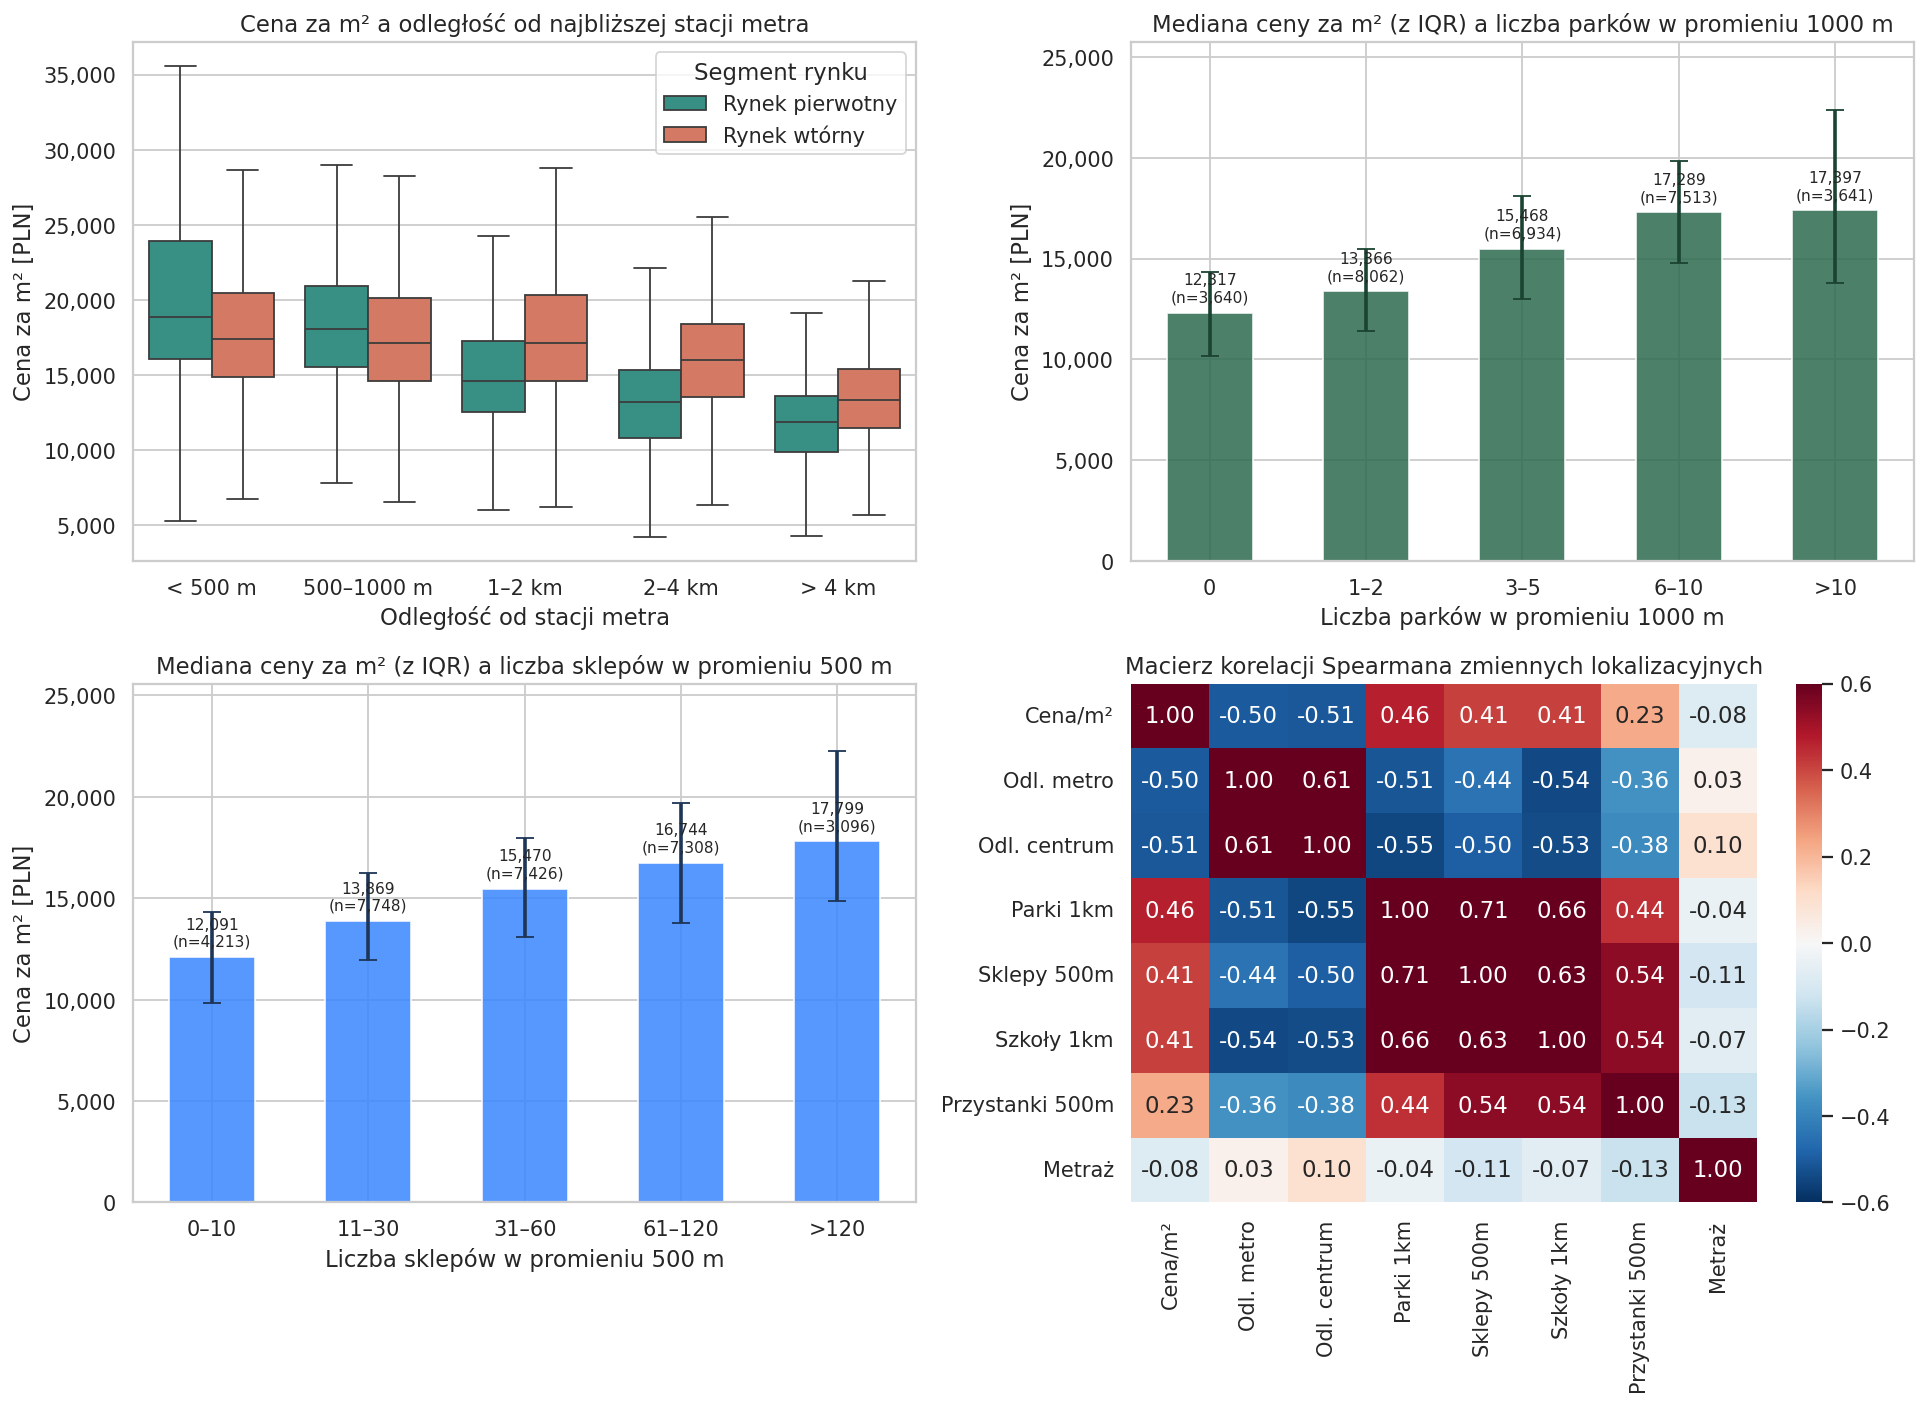

In [18]:
spatial_cols = ['cena_m2', 'distance_metro_m', 'distance_center_km', 'parks_1000m', 'shops_500m', 'schools_1000m', 'bus_stops_500m', 'LOK_POW_UZYT']
corr_summary = pd.DataFrame({
    'Korelacja_Pearsona': df_clean[spatial_cols].corr(method='pearson')['cena_m2'].drop('cena_m2'),
    'Korelacja_Spearmana': df_clean[spatial_cols].corr(method='spearman')['cena_m2'].drop('cena_m2')
}).sort_values('Korelacja_Spearmana', key=abs, ascending=False)
print("Korelacje cech przestrzennych i metrażu z ceną za m²:")
print(corr_summary)

metro_stats = df_clean.groupby('strefa_metro', observed=False).agg(
    Liczba_transakcji=('gid', 'count'),
    Mediana_cena_m2=('cena_m2', 'median'),
    Srednia_cena_m2=('cena_m2', 'mean')
)
print("\nMediana i średnia ceny za m² według odległości od stacji metra:")
print(metro_stats)

df_clean['parks_bin'] = pd.cut(df_clean['parks_1000m'], bins=[-1, 0, 2, 5, 10, 50], labels=['0', '1–2', '3–5', '6–10', '>10'])
df_clean['shops_bin'] = pd.cut(df_clean['shops_500m'], bins=[-1, 10, 30, 60, 120, 600], labels=['0–10', '11–30', '31–60', '61–120', '>120'])

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

sns.boxplot(
    data=df_clean, x='strefa_metro', y='cena_m2', hue='rynek',
    showfliers=False, palette=['#2a9d8f', '#e76f51'], ax=axes[0, 0]
)
axes[0, 0].set_title('Cena za m² a odległość od najbliższej stacji metra')
axes[0, 0].set_xlabel('Odległość od stacji metra')
axes[0, 0].set_ylabel('Cena za m² [PLN]')
axes[0, 0].yaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
axes[0, 0].legend(title='Segment rynku')

park_grp = df_clean.groupby('parks_bin', observed=False)['cena_m2'].agg(
    med='median', q25=lambda x: x.quantile(0.25), q75=lambda x: x.quantile(0.75), cnt='count'
).reset_index()
axes[0, 1].bar(park_grp['parks_bin'], park_grp['med'], color='#2d6a4f', alpha=0.85, width=0.55)
axes[0, 1].errorbar(park_grp['parks_bin'], park_grp['med'],
                    yerr=[park_grp['med'] - park_grp['q25'], park_grp['q75'] - park_grp['med']],
                    fmt='none', ecolor='#1b4332', elinewidth=2, capsize=5)
for idx, r in park_grp.iterrows():
    axes[0, 1].text(idx, r['med'] + 400, f"{r['med']:,.0f}\n(n={r['cnt']:,})", ha='center', va='bottom', fontsize=8.5)
axes[0, 1].set_ylim(0, park_grp['q75'].max() * 1.15)
axes[0, 1].set_title('Mediana ceny za m² (z IQR) a liczba parków w promieniu 1000 m')
axes[0, 1].set_xlabel('Liczba parków w promieniu 1000 m')
axes[0, 1].set_ylabel('Cena za m² [PLN]')
axes[0, 1].yaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))

shop_grp = df_clean.groupby('shops_bin', observed=False)['cena_m2'].agg(
    med='median', q25=lambda x: x.quantile(0.25), q75=lambda x: x.quantile(0.75), cnt='count'
).reset_index()
axes[1, 0].bar(shop_grp['shops_bin'], shop_grp['med'], color='#3a86ff', alpha=0.85, width=0.55)
axes[1, 0].errorbar(shop_grp['shops_bin'], shop_grp['med'],
                    yerr=[shop_grp['med'] - shop_grp['q25'], shop_grp['q75'] - shop_grp['med']],
                    fmt='none', ecolor='#1d3557', elinewidth=2, capsize=5)
for idx, r in shop_grp.iterrows():
    axes[1, 0].text(idx, r['med'] + 400, f"{r['med']:,.0f}\n(n={r['cnt']:,})", ha='center', va='bottom', fontsize=8.5)
axes[1, 0].set_ylim(0, shop_grp['q75'].max() * 1.15)
axes[1, 0].set_title('Mediana ceny za m² (z IQR) a liczba sklepów w promieniu 500 m')
axes[1, 0].set_xlabel('Liczba sklepów w promieniu 500 m')
axes[1, 0].set_ylabel('Cena za m² [PLN]')
axes[1, 0].yaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))

corr_matrix = df_clean[spatial_cols].corr(method='spearman')
labels_pl = ['Cena/m²', 'Odl. metro', 'Odl. centrum', 'Parki 1km', 'Sklepy 500m', 'Szkoły 1km', 'Przystanki 500m', 'Metraż']
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-0.6, vmax=0.6,
            xticklabels=labels_pl, yticklabels=labels_pl, ax=axes[1, 1])
axes[1, 1].set_title('Macierz korelacji Spearmana zmiennych lokalizacyjnych')

plt.tight_layout()
plt.show()

### 3.5. Przestrzenny rozkład cen za $m^2$ na mapie Warszawy

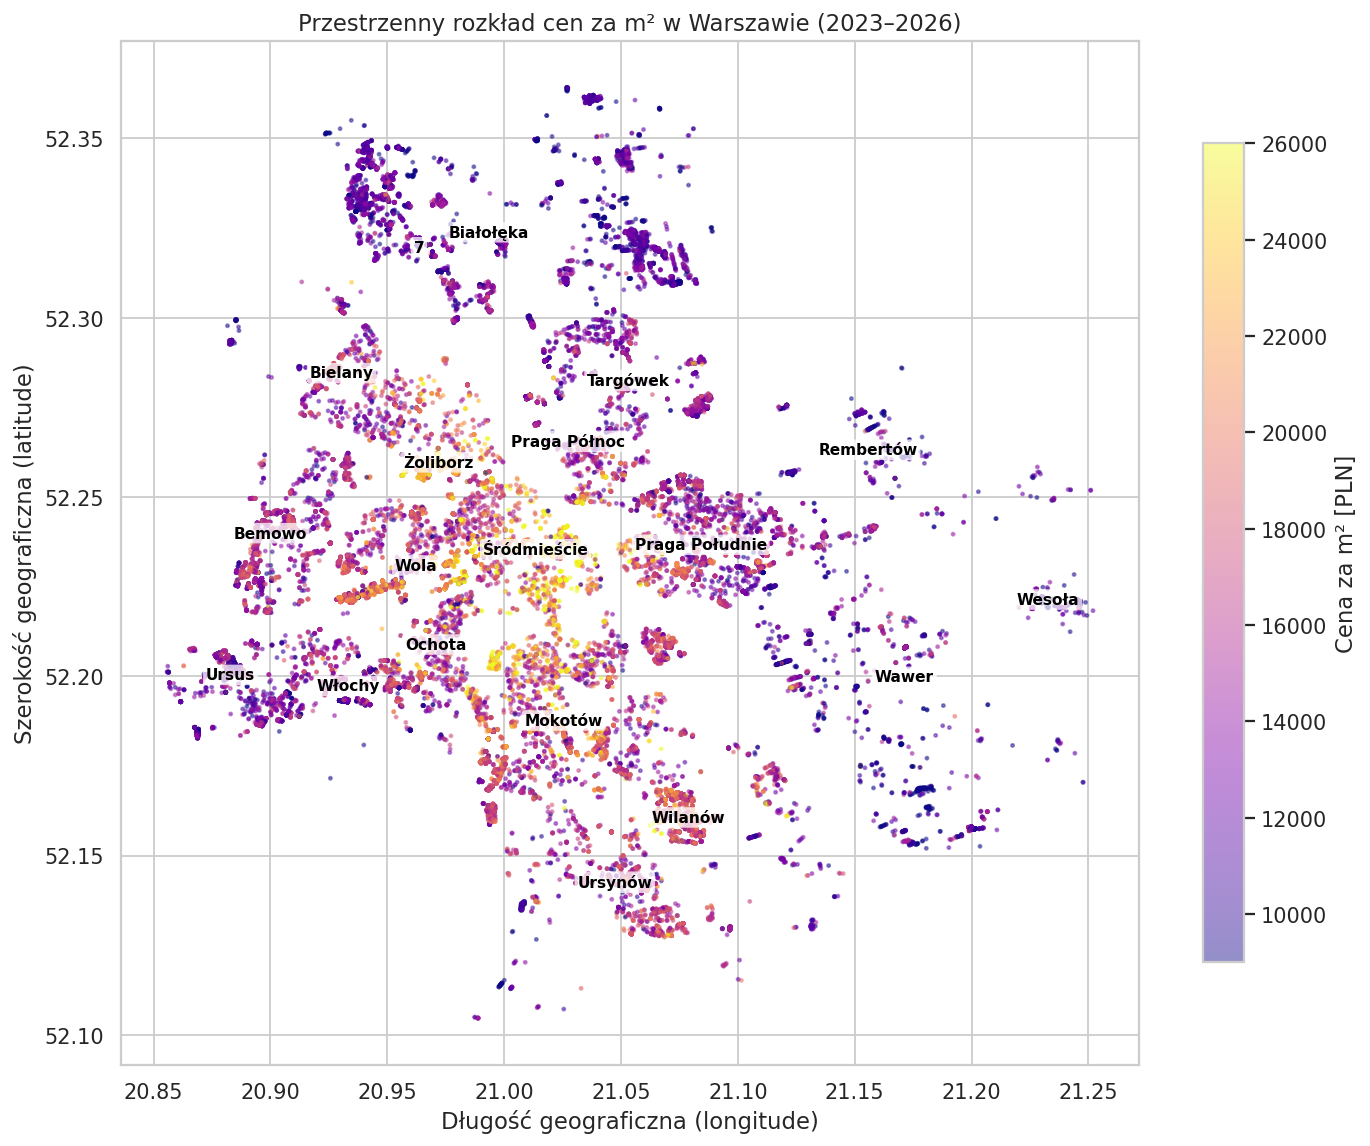

In [20]:
# Konwersja współrzędnych i ceny na typ numeryczny (zamienia m.in. 'True' na NaN)
for col in ['longitude', 'latitude', 'cena_m2']:
    df_clean[col] = pd.to_numeric(
        df_clean[col].astype(str).str.replace(',', '.', regex=False).str.strip(),
        errors='coerce'
    )

# Odfiltrowanie braków oraz ewentualnych przesuniętych wartości spoza granic Warszawy
df_map = df_clean.dropna(subset=['longitude', 'latitude', 'cena_m2']).copy()
df_map = df_map[
    df_map['longitude'].between(20.7, 21.4) &
    df_map['latitude'].between(52.0, 52.45)
]

fig, ax = plt.subplots(figsize=(11, 9))
sc = ax.scatter(
    df_map['longitude'], df_map['latitude'],
    c=df_map['cena_m2'], cmap='plasma',
    s=3, alpha=0.45, vmin=9000, vmax=26000
)
cbar = plt.colorbar(sc, ax=ax, shrink=0.8)
cbar.set_label('Cena za m² [PLN]')

centroids = df_map.groupby('district')[['longitude', 'latitude']].median()
for dist_name, row in centroids.iterrows():
    if pd.notna(row['longitude']) and pd.notna(row['latitude']):
        ax.text(
            row['longitude'], row['latitude'], dist_name,
            fontsize=8.5, fontweight='bold', ha='center', va='center', color='black',
            bbox=dict(boxstyle='round,pad=0.18', facecolor='white', alpha=0.75, edgecolor='none')
        )

ax.set_title('Przestrzenny rozkład cen za m² w Warszawie (2023–2026)')
ax.set_xlabel('Długość geograficzna (longitude)')
ax.set_ylabel('Szerokość geograficzna (latitude)')
plt.tight_layout()
plt.show()

### 3.6. Kluczowe wnioski z analizy (Etap 2 i Etap 3)
1. **Jakość danych RCN:** Z 89 738 rekordów surowych po odrzuceniu transakcji nie-wolnorynkowych (bonifikaty, przetargi, egzekucje), udziałów ułamkowych (`NIER_UDZIAL != 1/1`), niejednoznacznych pakietów wielolokalowych, duplikatów oraz wartości skrajnych pozostaje **87 191 wiarygodnych transakcji** (97,16% zbioru). Wykorzystanie `LOK_CENA_BRUTTO` zamiast `TRAN_CENA_BRUTTO` eliminuje zawyżenie ceny za $m^2$ przez miejsca postojowe i komórki lokatorskie.
2. **Zróżnicowanie dzielnicowe:** Najwyższe mediany cen za $m^2$ osiągają **Żoliborz** (20 396 PLN/m²), **Śródmieście** (20 216 PLN/m²) oraz **Wola** (18 466 PLN/m²), natomiast najniższe **Wawer** (11 062 PLN/m²), **Rembertów** (11 148 PLN/m²) i **Wesoła** (11 640 PLN/m²).
3. **Trendy 2023–2026:** Najwyższy skok mediany ceny za $m^2$ nastąpił między 2023 a 2024 rokiem (+18,74% r/r, z 12 950 do 15 377 PLN/m²). W 2025 r. nastąpiła stabilizacja (15 533 PLN/m², +1,02% r/r) przy rekordowym wolumenie (31 142 transakcje), a w danych za 2026 r. mediana osiąga 16 607 PLN/m² (+6,91% r/r).
4. **Rynek pierwotny vs wtórny:** Rynek wtórny odpowiada za 54,03% obrotu (47 110 transakcji) i w skali całego miasta ma wyższą medianę ceny za $m^2$ (15 689 PLN/m², mediana metrażu 48,5 m²) niż rynek pierwotny (14 124 PLN/m², mediana metrażu 50,4 m²), co wynika z dużej podaży inwestycji deweloperskich w dzielnicach obrzeżnych (m.in. Białołęka, Ursus, Wawer).
5. **Wpływ infrastruktury:** Najsilniejszą ujemną korelację z ceną za $m^2$ wykazują **odległość od centrum** ($r_p = -0,51$, $r_s = -0,49$) oraz **odległość od stacji metra** ($r_p = -0,44$, $r_s = -0,46$). Dodatnio z ceną korelują dostęp do **parków w promieniu 1000 m** ($r_s = +0,39$), **szkół w promieniu 1000 m** ($r_s = +0,39$) oraz **sklepów w promieniu 500 m** ($r_s = +0,37$).